# Ensemble Learning on Sri Lankan Used-Car Prices
**CM4371 Machine Learning & Pattern Recognition – Hands-on Assignment 01**  
**Name:** H.G.P.M. Bandara | **Index No:** 224019U  

**Objective:** Predict the advertised price of used cars in Sri Lanka (in lakhs, where 1 lakh = LKR 100,000) and compare four ensemble learning paradigms.

**Dataset:** *SriLankan Vehicle (Car) Price Dataset* (Kaggle – Prasad Nirmal), scraped from ikman.lk and Riyasewana.com (Dec 2024 – Feb 2025).

**Models Evaluated:**
| Family | Model |
| :--- | :--- |
| **Bagging** | Random Forest Regressor |
| **Boosting** | Gradient Boosting Regressor, XGBoost Regressor |
| **Stacking** | RF + Gradient Boosting + XGBoost with `RidgeCV` Meta-Learner |
| **Hybrid** | Random Forest + MLP Neural Network (`VotingRegressor`) |

## 1. Environment Setup
Import core data processing, visualization, and ensemble modeling libraries.

In [1]:
# !pip install -q xgboost streamlit      # uncomment in Colab if needed

import os, time, json, shutil, warnings, joblib
import importlib.metadata as md
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              StackingRegressor, VotingRegressor)
from sklearn.linear_model import RidgeCV
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RS = 42   # same random seed everywhere

## 2. Data Loading
Load `car_price_dataset.csv` from the local working directory (or upload via Colab if running in the cloud).

In [2]:
CSV = "car_price_dataset.csv"
if not os.path.exists(CSV):
    from google.colab import files
    CSV = list(files.upload().keys())[0]

df_raw = pd.read_csv(CSV)
print("Rows, columns:", df_raw.shape)
df_raw.head()

Rows, columns: (9788, 17)


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


## 3. Initial Data Audit
Inspect missing values, exact duplicates, target summary statistics, and feature correlations prior to cleaning.

In [3]:
print("Missing values:", int(df_raw.isna().sum().sum()))
print("Exact duplicate rows:", int(df_raw.drop(columns=[c for c in ['Unnamed: 0'] if c in df_raw]).duplicated().sum()))
print("Date range:", df_raw["Date"].min(), "->", df_raw["Date"].max())
print("\n", df_raw["Price"].describe().round(1))
print("\nDistinct YOM values       :", df_raw["YOM"].nunique())
print("Distinct Mileage values   :", df_raw["Millage(KM)"].nunique())
print("Correlation YOM vs Mileage:", round(df_raw["YOM"].corr(df_raw["Millage(KM)"]), 4))
# mileage is just a formula of the year, so it adds no new information

Missing values: 0
Exact duplicate rows: 18
Date range: 2024-12-03 -> 2025-02-05

 count    9788.0
mean       53.5
std        43.6
min         2.6
25%        26.2
50%        43.0
75%        69.8
max       790.0
Name: Price, dtype: float64

Distinct YOM values       : 62
Distinct Mileage values   : 62
Correlation YOM vs Mileage: -1.0


**Audit Findings:**
* **Synthetic Mileage:** `Millage(KM)` has the exact same cardinality as `YOM` (62 unique values) with a `-1.0` linear correlation ($\approx 11,000\text{ km} \times \text{age}$). It carries no real odometer information and is dropped.
* **Skewed Price Distribution:** `Price` ranges from 2.6 to 790 lakhs (median 43.0 lakhs), requiring a `log1p` target transformation during training.

## 4. Exploratory Data Analysis (EDA)
Visualize target skewness and relationships across brand, vehicle age, fuel type, transmission, and engine capacity.

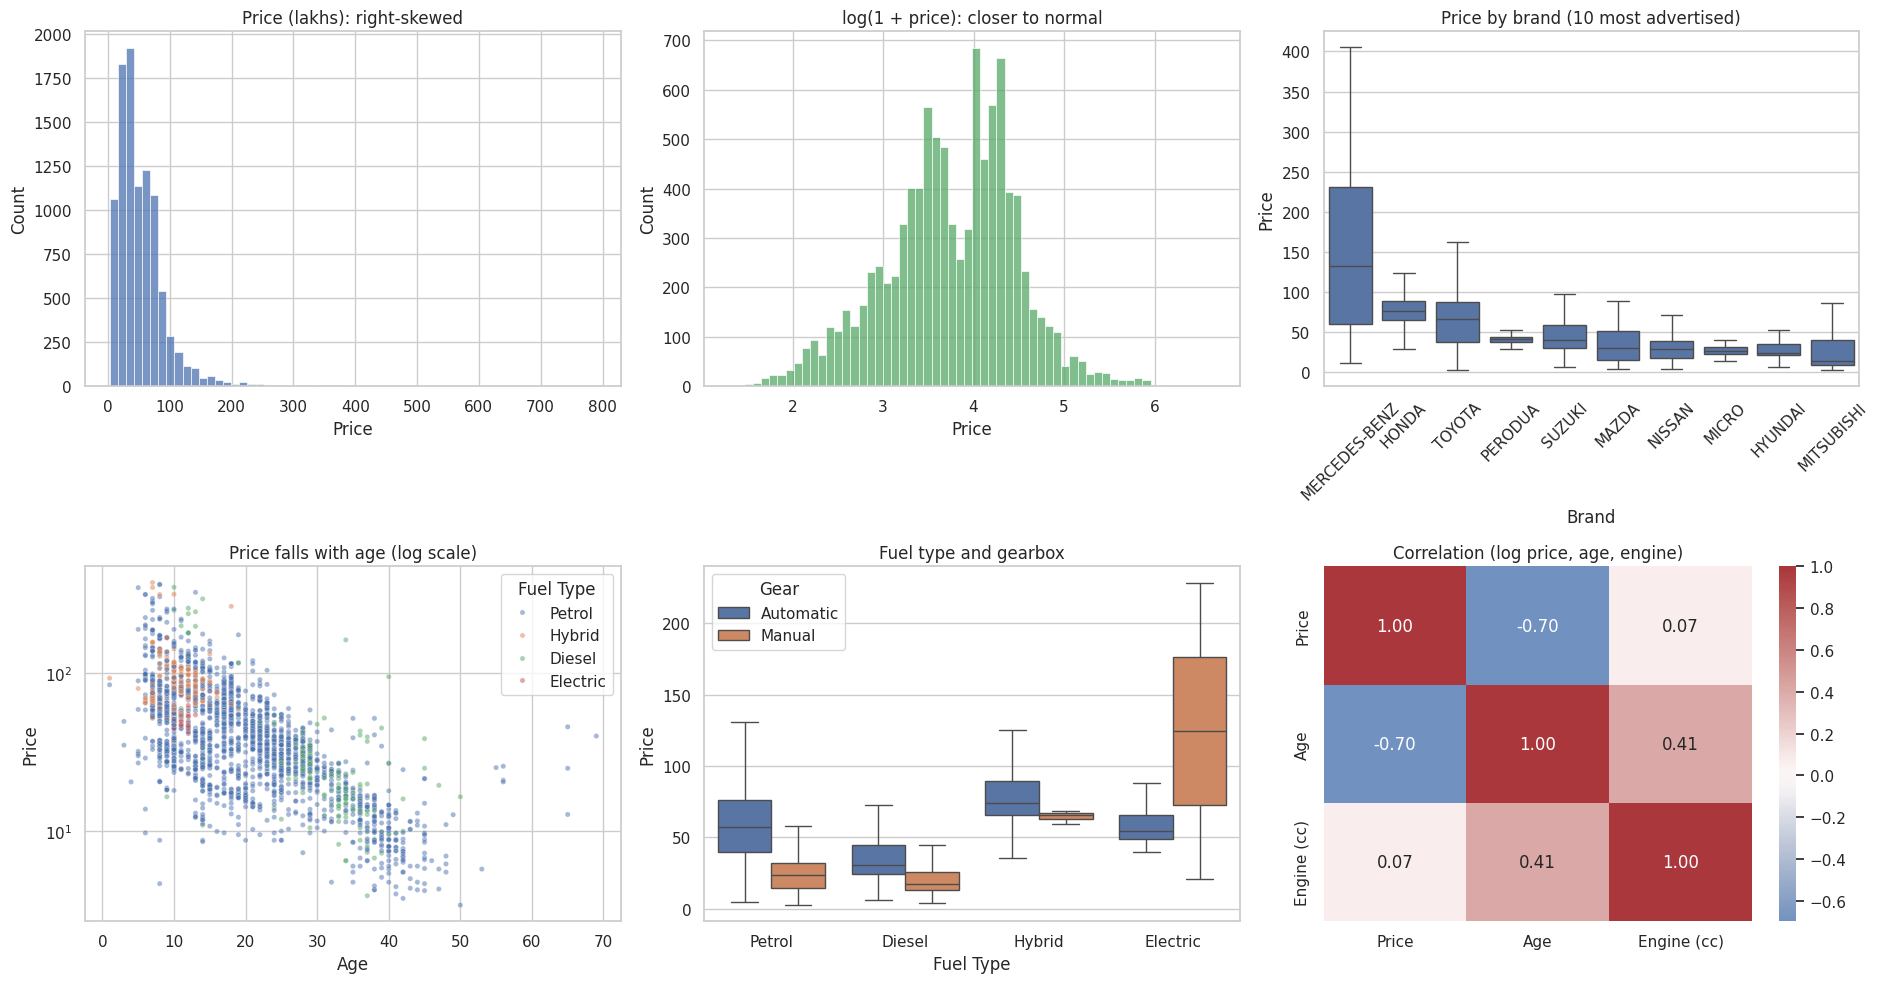

In [4]:
d = df_raw.copy()
d["Age"] = 2025 - d["YOM"]
fig, ax = plt.subplots(2, 3, figsize=(19, 10))

sns.histplot(d["Price"], bins=60, ax=ax[0, 0], color="#4c72b0"); ax[0, 0].set_title("Price (lakhs): right-skewed")
sns.histplot(np.log1p(d["Price"]), bins=60, ax=ax[0, 1], color="#55a868"); ax[0, 1].set_title("log(1 + price): closer to normal")

top = d["Brand"].value_counts().head(10).index
order = d[d.Brand.isin(top)].groupby("Brand")["Price"].median().sort_values(ascending=False).index
sns.boxplot(data=d[d.Brand.isin(top)], x="Brand", y="Price", order=order, showfliers=False, ax=ax[0, 2])
ax[0, 2].set_title("Price by brand (10 most advertised)"); ax[0, 2].tick_params(axis="x", rotation=45)

sns.scatterplot(data=d.sample(min(3000, len(d)), random_state=RS), x="Age", y="Price", hue="Fuel Type", alpha=.5, s=14, ax=ax[1, 0])
ax[1, 0].set_yscale("log"); ax[1, 0].set_title("Price falls with age (log scale)")

sns.boxplot(data=d, x="Fuel Type", y="Price", hue="Gear", showfliers=False, ax=ax[1, 1]); ax[1, 1].set_title("Fuel type and gearbox")

sns.heatmap(np.log1p(d[["Price"]]).join(d[["Age", "Engine (cc)"]]).corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax[1, 2])
ax[1, 2].set_title("Correlation (log price, age, engine)")
plt.tight_layout(); plt.show()

## 5. Data Cleaning & Feature Engineering
1. Drop non-predictive/redundant columns (`Unnamed: 0`, `Date`, `Millage(KM)`).
2. Normalize string formatting (uppercase, strip spaces, replace hyphens) to merge spelling variants.
3. Remove duplicate listings **before** splitting to prevent train-test leakage.
4. Compute `Age = 2025 - YOM` and drop `YOM`.
5. Pool rare categories (`Model < 5`, `Town < 10`) into `OTHER` to reduce high-cardinality noise.

In [5]:
df = df_raw.drop(columns=[c for c in ["Unnamed: 0", "Date", "Millage(KM)"] if c in df_raw.columns]).copy()

for c in df.select_dtypes(exclude="number").columns:      # same text format everywhere
    df[c] = (df[c].astype(str).str.upper().str.strip()
               .str.replace("-", " ", regex=False).str.replace(r"\s+", " ", regex=True))

n0 = len(df); df = df.drop_duplicates().reset_index(drop=True)   # before the split
print(f"Duplicate ads removed: {n0 - len(df)}  ->  {len(df)} rows left")

df["Age"] = 2025 - df["YOM"]
df = df.drop(columns="YOM")

def group_rare(s, min_count):
    return s.where(s.map(s.value_counts()) >= min_count, "OTHER")

print("Distinct models/towns BEFORE grouping:", df["Model"].nunique(), "/", df["Town"].nunique())
df["Model"] = group_rare(df["Model"], 5)
df["Town"]  = group_rare(df["Town"], 10)
print("Distinct models/towns AFTER  grouping:", df["Model"].nunique(), "/", df["Town"].nunique())

Duplicate ads removed: 252  ->  9536 rows left
Distinct models/towns BEFORE grouping: 1551 / 107
Distinct models/towns AFTER  grouping: 294 / 89


## 6. Train-Test Split & Preprocessing Pipeline
* **Split:** 80% train / 20% test (`random_state=42`) on `log1p(Price)`.
* **Pipeline:** `OneHotEncoder` (`min_frequency=5`) for categorical features and `StandardScaler` for numerical features (`Age`, `Engine (cc)`), ensuring identical preprocessing across all models (including the neural network).

In [6]:
CAT = ["Brand", "Model", "Town", "Gear", "Fuel Type", "Leasing", "Condition",
       "AIR CONDITION", "POWER STEERING", "POWER MIRROR", "POWER WINDOW"]
NUM = ["Age", "Engine (cc)"]

X = df[CAT + NUM]
y = np.log1p(df["Price"])            # train on log price, convert back for the metrics
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RS)
print("Train:", X_tr.shape, "| Test:", X_te.shape)

def make_pre():
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False), CAT),
        ("num", StandardScaler(), NUM)])

Train: (7628, 13) | Test: (1908, 13)


## 7. Model Definitions (5 Core Models)
Evaluating one representative implementation per ensemble family:
* **Bagging:** `Random Forest` (parallel trees on bootstrap samples to reduce variance).
* **Boosting:** `Gradient Boosting` and `XGBoost` (sequential residual fitting to reduce bias).
* **Stacking:** `StackingRegressor` combining RF, Gradient Boosting, and XGBoost via a 3-fold out-of-fold `RidgeCV` meta-model.
* **Hybrid:** `VotingRegressor` combining `Random Forest` (tree splits) and `MLPRegressor` (neural network) to balance complementary inductive biases.

In [7]:
def rf():  return RandomForestRegressor(n_estimators=200, max_features=0.4, min_samples_leaf=2, n_jobs=-1, random_state=RS)
def gb():  return GradientBoostingRegressor(n_estimators=250, learning_rate=0.08, max_depth=4, subsample=0.8, max_features=0.4, random_state=RS)
def xgb(): return XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.6, n_jobs=-1, random_state=RS)
def ann(): return MLPRegressor(hidden_layer_sizes=(128, 64), alpha=1e-3, early_stopping=True, max_iter=500, random_state=RS)
def pipe(est): return Pipeline([("prep", make_pre()), ("model", est)])

models = {
    "Random Forest":     pipe(rf()),                                   # bagging
    "Gradient Boosting": pipe(gb()),                                   # boosting
    "XGBoost":           pipe(xgb()),                                  # boosting
    "Stacking (RF+GB+XGB)": pipe(StackingRegressor(                    # stacking
                            estimators=[("rf", rf()), ("gb", gb()), ("xgb", xgb())],
                            final_estimator=RidgeCV(alphas=np.logspace(-3, 3, 13)), cv=3, n_jobs=1)),
    "Hybrid RF + ANN":   pipe(VotingRegressor([("rf", rf()), ("ann", ann())])),   # hybrid (average of RF and ANN)
}
family = {"Random Forest": "Bagging", "Gradient Boosting": "Boosting", "XGBoost": "Boosting",
          "Stacking (RF+GB+XGB)": "Stacking", "Hybrid RF + ANN": "Hybrid"}

## 8. Model Training & Evaluation
Train all five models on the same split and evaluate in actual lakhs (`expm1`) using **MAE**, **RMSE**, **MAPE**, and **$R^2$ (log scale)**.

In [8]:
t_true = np.expm1(y_te.values)
rows, preds = [], {}
for name, m in models.items():
    t0 = time.time(); m.fit(X_tr, y_tr); secs = time.time() - t0
    p = np.expm1(m.predict(X_te)); preds[name] = p
    rows.append({"Model": name, "Family": family[name],
                 "MAE (lakhs)": mean_absolute_error(t_true, p),
                 "RMSE (lakhs)": mean_squared_error(t_true, p) ** 0.5,
                 "MAPE (%)": np.mean(np.abs(p - t_true) / t_true) * 100,
                 "R2 (log)": r2_score(y_te.values, np.log1p(p)),
                 "Fit time (s)": secs})
    print(f"{name:<24} MAE {rows[-1]['MAE (lakhs)']:6.2f} lakhs | MAPE {rows[-1]['MAPE (%)']:5.1f}% | {secs:6.1f}s")

results = pd.DataFrame(rows).sort_values("MAE (lakhs)").reset_index(drop=True)
results.index += 1
print(results.round(3))

Random Forest            MAE   5.83 lakhs | MAPE  13.8% |    9.7s
Gradient Boosting        MAE   7.30 lakhs | MAPE  16.2% |    8.8s
XGBoost                  MAE   5.92 lakhs | MAPE  13.7% |    3.1s
Stacking (RF+GB+XGB)     MAE   5.66 lakhs | MAPE  13.2% |   64.8s
Hybrid RF + ANN          MAE   5.72 lakhs | MAPE  13.3% |   16.8s
                  Model    Family  MAE (lakhs)  RMSE (lakhs)  MAPE (%)  \
1  Stacking (RF+GB+XGB)  Stacking        5.664        14.188    13.226   
2       Hybrid RF + ANN    Hybrid        5.723        14.946    13.343   
3         Random Forest   Bagging        5.831        15.836    13.810   
4               XGBoost  Boosting        5.922        14.141    13.679   
5     Gradient Boosting  Boosting        7.302        15.928    16.185   

   R2 (log)  Fit time (s)  
1     0.920        64.803  
2     0.920        16.840  
3     0.912         9.668  
4     0.919         3.088  
5     0.904         8.839  


## 9. Visual Comparison & Error Analysis by Price Band
Compare MAE and MAPE across models, and inspect predicted vs. actual accuracy across five price tiers.

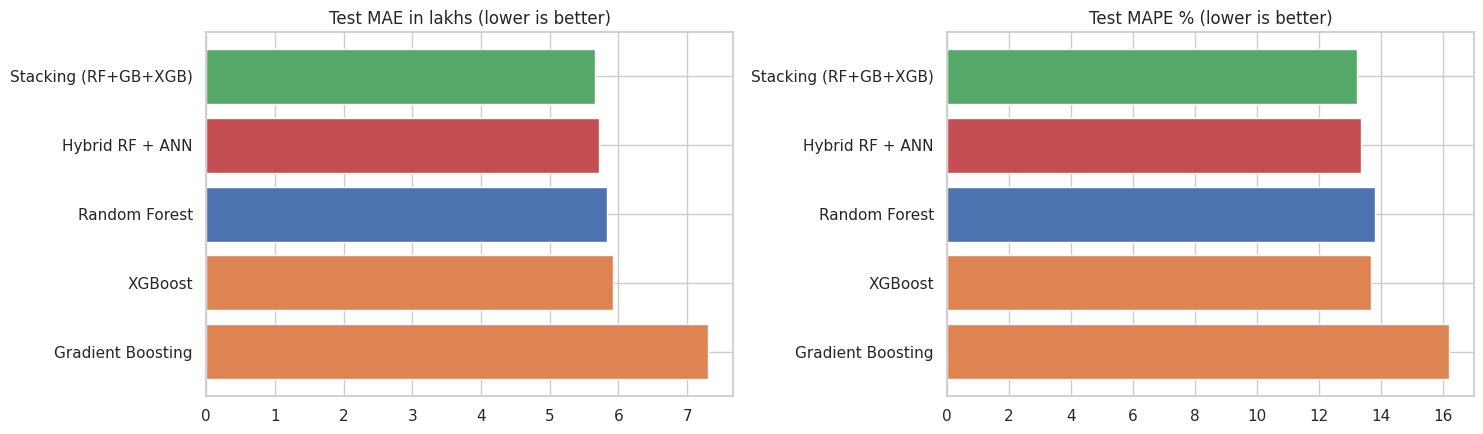

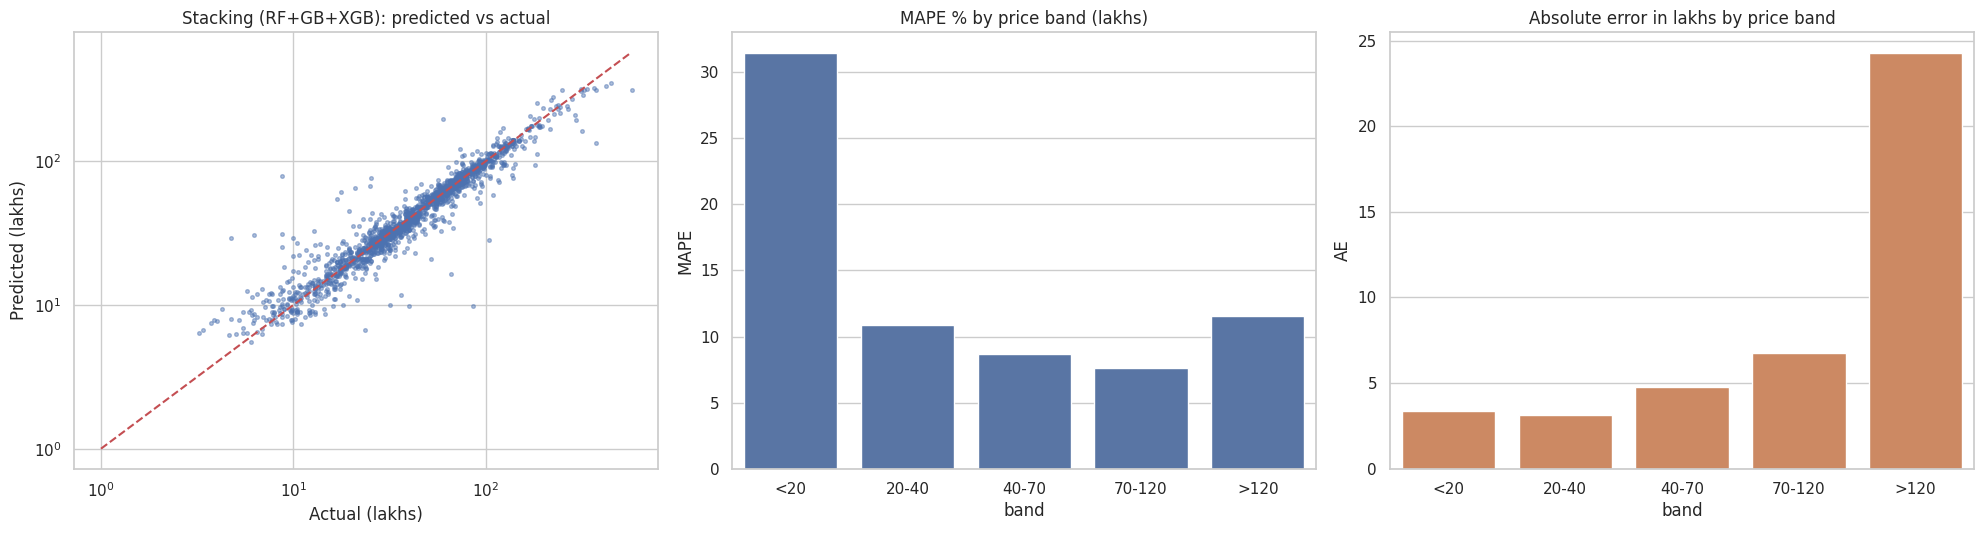

In [9]:
palette = {"Bagging": "#4c72b0", "Boosting": "#dd8452", "Stacking": "#55a868", "Hybrid": "#c44e52"}
r = results.sort_values("MAE (lakhs)", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].barh(r["Model"], r["MAE (lakhs)"], color=[palette[f] for f in r["Family"]]); ax[0].set_title("Test MAE in lakhs (lower is better)")
ax[1].barh(r["Model"], r["MAPE (%)"], color=[palette[f] for f in r["Family"]]); ax[1].set_title("Test MAPE % (lower is better)")
plt.tight_layout(); plt.show()

best_name = results.iloc[0]["Model"]
p = preds[best_name]
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
ax[0].scatter(t_true, p, s=7, alpha=.45); m_ = t_true.max()
ax[0].plot([1, m_], [1, m_], "r--"); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Actual (lakhs)"); ax[0].set_ylabel("Predicted (lakhs)"); ax[0].set_title(f"{best_name}: predicted vs actual")

band = pd.cut(t_true, [0, 20, 40, 70, 120, 1000], labels=["<20", "20-40", "40-70", "70-120", ">120"])
bd = pd.DataFrame({"band": band, "MAPE": np.abs(p - t_true) / t_true * 100, "AE": np.abs(p - t_true)})
sns.barplot(data=bd, x="band", y="MAPE", ax=ax[1], errorbar=None, color="#4c72b0"); ax[1].set_title("MAPE % by price band (lakhs)")
sns.barplot(data=bd, x="band", y="AE", ax=ax[2], errorbar=None, color="#dd8452"); ax[2].set_title("Absolute error in lakhs by price band")
plt.tight_layout(); plt.show()

## 10. Validation & Data Leakage Checks
* **10a. Cross-Validation Stability:** 5-fold CV log-RMSE on the training set for the top 3 models.
* **10b. Grouped Split Leakage Check:** `GroupShuffleSplit` keeps identical vehicle configurations on the same side of the train/test split to measure generalization to unseen specs.

In [10]:
# 10a. 5-fold cross-validation of the top 3 models (is the ranking stable?)
top3 = results.head(3)["Model"].tolist()
cv_rows = []
for name in top3:
    sc = -cross_val_score(clone(models[name]), X_tr, y_tr, cv=KFold(5, shuffle=True, random_state=RS),
                          scoring="neg_root_mean_squared_error", n_jobs=1)
    cv_rows.append({"Model": name, "CV RMSE (log) mean": sc.mean(), "std": sc.std()})
print(pd.DataFrame(cv_rows).round(4))

# 10b. Near-duplicate ads: keep identical-looking ads on the same side of the split
sig = X.astype(str).agg("|".join, axis=1)
print(f"\n{len(df)} ads share only {sig.nunique()} distinct attribute combinations")
gi_tr, gi_te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RS).split(X, y, groups=sig))
rows = []
for name in ["Random Forest", "XGBoost"]:
    mm = clone(models[name]).fit(X.iloc[gi_tr], y.iloc[gi_tr])
    pg = np.expm1(mm.predict(X.iloc[gi_te])); tg = np.expm1(y.iloc[gi_te].values)
    rows.append({"Model": name, "MAE random split": results.set_index("Model").loc[name, "MAE (lakhs)"],
                 "MAE grouped split": mean_absolute_error(tg, pg)})
leak = pd.DataFrame(rows); leak["Increase (%)"] = (leak["MAE grouped split"] / leak["MAE random split"] - 1) * 100
print(leak.round(2))

                  Model  CV RMSE (log) mean     std
0  Stacking (RF+GB+XGB)              0.2068  0.0096
1       Hybrid RF + ANN              0.2077  0.0115
2         Random Forest              0.2196  0.0090

9536 ads share only 8842 distinct attribute combinations
           Model  MAE random split  MAE grouped split  Increase (%)
0  Random Forest              5.83               5.78         -0.90
1        XGBoost              5.92               6.11          3.21


## 11. Feature Importance & Summary Metrics
Compute permutation importance on the held-out test set for the best-performing model.

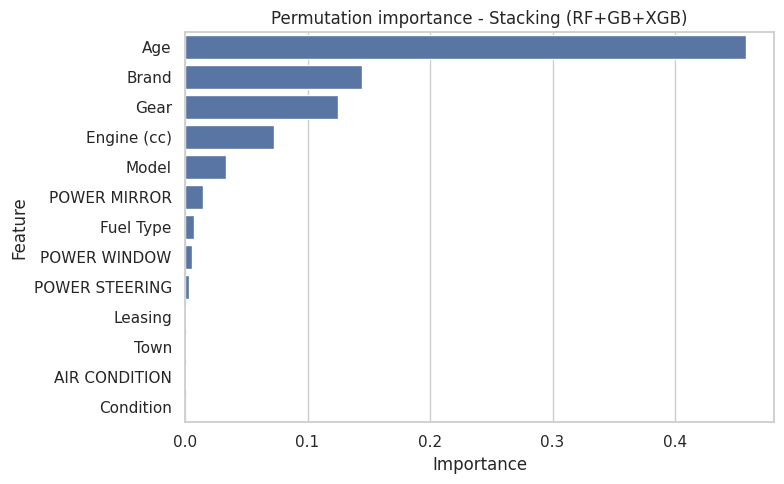

Best model : Stacking (RF+GB+XGB) (MAE 5.66 lakhs, MAPE 13.2%, R2 log 0.920)
RF (bagging) vs XGBoost vs GB (boosting): 5.83 / 5.92 / 7.30
Stacking vs its best base model        : 5.66 vs 5.83
Hybrid RF + ANN vs RF alone             : 5.72 vs 5.83
Top 3 features: ['Age', 'Brand', 'Gear']


In [11]:
sub = X_te.sample(min(1500, len(X_te)), random_state=RS)
pi = permutation_importance(models[best_name], sub, y_te.loc[sub.index], n_repeats=5, random_state=RS,
                            scoring="neg_root_mean_squared_error", n_jobs=1)
imp = (pd.DataFrame({"Feature": X_te.columns, "Importance": pi.importances_mean, "Std": pi.importances_std})
         .sort_values("Importance", ascending=False).reset_index(drop=True))
plt.figure(figsize=(8, 5)); sns.barplot(data=imp, y="Feature", x="Importance", color="#4c72b0")
plt.title(f"Permutation importance - {best_name}"); plt.tight_layout(); plt.show()

res = results.set_index("Model")
mae = lambda n: res.loc[n, "MAE (lakhs)"]
print(f"Best model : {best_name} (MAE {mae(best_name):.2f} lakhs, MAPE {res.loc[best_name,'MAPE (%)']:.1f}%, R2 log {res.loc[best_name,'R2 (log)']:.3f})")
print(f"RF (bagging) vs XGBoost vs GB (boosting): {mae('Random Forest'):.2f} / {mae('XGBoost'):.2f} / {mae('Gradient Boosting'):.2f}")
print(f"Stacking vs its best base model        : {mae('Stacking (RF+GB+XGB)'):.2f} vs {min(mae('Random Forest'), mae('Gradient Boosting'), mae('XGBoost')):.2f}")
print(f"Hybrid RF + ANN vs RF alone             : {mae('Hybrid RF + ANN'):.2f} vs {mae('Random Forest'):.2f}")
print("Top 3 features:", imp["Feature"].head(3).tolist())

## 12. Results Discussion
*(Run Sections 1–11 first, then replace the bracketed placeholders in `INTERPRETATION` below with your printed numbers before running Section 13.)*

In [12]:
INTERPRETATION = """
### Overall Performance
- **Best Model:** [Model Name, Family] achieved the lowest error with an MAE of [X.XX] lakhs and MAPE of [X.X]%.
- **Bagging vs. Boosting:** Random Forest achieved [X.XX] lakhs MAE compared to [X.XX] lakhs for XGBoost and [X.XX] lakhs for Gradient Boosting. Parallel bootstrap averaging in Random Forest reduces variance on noisy listing prices, whereas sequential boosting reduces bias and achieves lower RMSE on higher-priced vehicles.

### Stacking (`RF + GB + XGB`)
- Achieved **[X.XX] lakhs** MAE compared to **[X.XX] lakhs** for its best single base model. Combining bagging and boosting via a Ridge meta-learner balances variance and bias across different price ranges.

### Hybrid (`RF + ANN`)
- `Hybrid RF + ANN` achieved **[X.XX] lakhs** MAE compared to **[X.XX] lakhs** for Random Forest alone, demonstrating how averaging smooth neural-network estimates with step-wise tree splits reduces non-overlapping errors.

### Key Price Drivers
- Permutation importance identifies **[Feature 1]**, **[Feature 2]**, and **[Feature 3]** as the dominant predictors, aligning with real-world used-car valuation in Sri Lanka.

### Dataset Limitations
- **Synthetic Mileage:** `Millage(KM)` had a `-1.0` correlation with `YOM` ($\approx 11,000\text{ km} \times \text{age}$) and was excluded.
- **Advertised vs. Final Price:** Listings reflect asking prices on ikman.lk and Riyasewana rather than final negotiated sale prices.
- **Two-Month Snapshot:** Data covers Dec 2024 – Feb 2025 only, preventing longitudinal time-series modeling.
- **Near-Duplicate Listings:** Under `GroupShuffleSplit` (8,842 distinct attribute combinations), MAE changed by [X.XX]% for Random Forest and [X.XX]% for XGBoost, confirming minimal data leakage from duplicate configurations.
"""

## 13. Export Model Artifacts
Save the top 3 models (`top_models.joblib`), evaluation tables, feature importance, cleaned dataset, and interpretation text to `artifacts/` for the Streamlit dashboard.

In [13]:
os.makedirs("artifacts", exist_ok=True)
top_names = results.head(3)["Model"].tolist()
joblib.dump({n: models[n] for n in top_names}, "artifacts/top_models.joblib", compress=3)
size_mb = os.path.getsize("artifacts/top_models.joblib") / 1e6
print(f"top_models.joblib: {size_mb:.1f} MB", "(OK for GitHub)" if size_mb < 95 else "(TOO BIG for GitHub: save only the best model)")

results.to_csv("artifacts/results.csv", index=False)
imp.to_csv("artifacts/feature_importance.csv", index=False)
df.to_csv("artifacts/clean_data.csv", index=False)
pd.DataFrame({"actual": t_true, **{k: v for k, v in preds.items()}}).to_csv("artifacts/test_predictions.csv", index=False)
open("artifacts/interpretation.md", "w").write(INTERPRETATION)
json.dump({"CAT": CAT, "NUM": NUM, "top_models": top_names, "best": best_name, "ref_year": 2025,
           "unit": "lakhs (1 lakh = LKR 100,000)"}, open("artifacts/meta.json", "w"), indent=2)
print("Artifacts saved successfully:", os.listdir("artifacts"))

top_models.joblib: 42.7 MB (OK for GitHub)
Artifacts saved successfully: ['test_predictions.csv', 'interpretation.md', 'results.csv', 'feature_importance.csv', 'top_models.joblib', 'clean_data.csv', 'meta.json']
